<a href="https://colab.research.google.com/github/pauloricardopg/RedesNeuraisArtificiais-PPCOM/blob/main/Implementa%C3%A7%C3%A3o_do_Backpropagation_em_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
# ==========================================
# Importações e Funções Auxiliares
# ==========================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_blobs

def include_bias(X):
    return np.c_[np.ones(X.shape[0]), X]

def one_hot_encode(y, labels):
    y_hot = np.ones((y.shape[0], len(labels)), dtype=int) * (-1)
    for i, label in enumerate(labels):
        idxs = np.where(y == label)[0]
        y_hot[idxs, i] = 1
    return y_hot

In [14]:
# ==========================================
# Funções de Ativação e Derivadas
# ==========================================
def tanh(x): return np.tanh(x)
def dtanh(x): return 1 - np.tanh(x)**2

def relu(x): return np.maximum(0, x)
def drelu(x): return np.where(x > 0, 1, 0)

def sigmoid(x): return 1 / (1 + np.exp(-x))
def dsigmoid(x):
    s = sigmoid(x)
    return s * (1 - s)

# Dicionário para resgatar dinamicamente a função e sua derivada
activation_funcs = {
    'tanh': (tanh, dtanh),
    'relu': (relu, drelu),
    'sigmoid': (sigmoid, dsigmoid)
}

In [15]:
# ==========================================
# Classe do MLP Customizado
# ==========================================
class MultiLayer(BaseEstimator, ClassifierMixin):
    def __init__(self, n_hidden=[2], activations=['tanh'], max_iter=1000, learning_rate=0.002):
        self.max_iter = max_iter
        self.learning_rate = learning_rate
        self.n_hidden = n_hidden

        # Mapeia as funções de ativação: se passar só uma, replica para todas as camadas
        if len(activations) == 1:
            self.activations = activations * (len(n_hidden) + 1)
        else:
            if len(activations) != len(n_hidden) + 1:
                raise ValueError("Forneça uma função de ativação para cada camada (ocultas + saída) ou apenas uma para todas.")
            self.activations = activations

    def forward(self, X):
        self.A = []
        self.Z = []
        AUX = X.copy()

        for i, W in enumerate(self.Ws):
            self.A.append(include_bias(AUX))
            self.Z.append(self.A[-1] @ W)
            func, _ = activation_funcs[self.activations[i]]
            AUX = func(self.Z[-1])

        return AUX

    def backward(self, y, y_pred):
        grads = []

        # Cálculo da derivada da ativação de saída e do output_delta
        _, dfunc_out = activation_funcs[self.activations[-1]]
        act_grad_out = dfunc_out(self.Z[-1])
        output_delta = (y_pred - y) * act_grad_out

        output_grad = self.A[-1].T @ output_delta
        grads.append(output_grad)

        # Backpropagation nas camadas ocultas
        for i in range(len(self.Ws)-1, 0, -1):
            _, dfunc = activation_funcs[self.activations[i-1]]
            act_grad = dfunc(self.Z[i-1])
            input_delta = (output_delta @ self.Ws[i][1:].T) * act_grad
            grad = self.A[i-1].T @ input_delta
            grads.insert(0, grad)
            output_delta = input_delta.copy()

        # Atualização dos pesos
        for i in range(len(self.Ws)):
            self.Ws[i] -= self.learning_rate * grads[i]

        return self

    def fit(self, X, y):
        self.Ws = []
        previous_output = X.shape[1]

        # Inicialização com peso em escala menor (* 0.1) para evitar Dead ReLUs
        for n in self.n_hidden:
            self.Ws.append(np.random.randn(previous_output+1, n) * 0.1)
            previous_output = n

        self.labels = sorted(list(set(y)))
        y_enc = one_hot_encode(y, self.labels)

        # Inicialização da camada de saída
        self.Ws.append(np.random.randn(previous_output+1, y_enc.shape[1]) * 0.1)

        for _ in range(self.max_iter):
            logits = self.forward(X)
            self.backward(y_enc, logits)

        return self

    def predict(self, X):
        logits = self.forward(X)
        idxs = np.argmax(logits, axis=1)
        return np.array([self.labels[idx] for idx in idxs])

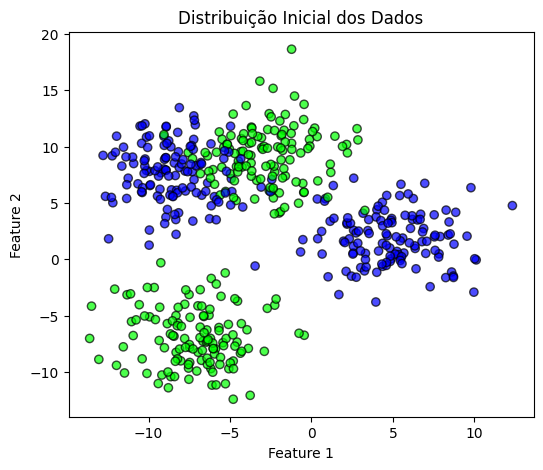

In [16]:
# ==========================================
# Geração do Dataset e Plotagem Inicial
# ==========================================
# Criando uma distribuição de dados mais complexa para desafiar o modelo
X, y = make_blobs(n_samples=500, centers=4, cluster_std=2.5, random_state=42)
y = np.where(y % 2 == 0, 1, -1)

plt.figure(figsize=(6, 5))
plt.title("Distribuição Inicial dos Dados")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.brg, edgecolors='k', alpha=0.7)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [17]:
# ==========================================
# Treinamento e Avaliação
# ==========================================
# Arquitetura: 2 camadas ocultas de 10 neurônios (ReLU) e saída com Tanh
hidden_layers = [10, 10]
acts = ['relu', 'relu', 'tanh']

# FIXANDO A SEMENTE AQUI:
np.random.seed(42)

# Treinamento do MLP Customizado
model_custom = MultiLayer(n_hidden=hidden_layers, activations=acts, max_iter=2000, learning_rate=0.001)
model_custom.fit(X, y)
y_pred_custom = model_custom.predict(X)

# Treinamento do Scikit-Learn
model_sklearn = MLPClassifier(hidden_layer_sizes=tuple(hidden_layers), activation='relu', max_iter=2000, learning_rate_init=0.001, random_state=42)
model_sklearn.fit(X, y)
y_pred_sklearn = model_sklearn.predict(X)

print(f"Acurácia MLP Customizado: {accuracy_score(y, y_pred_custom)}")
print(f"Acurácia Scikit-Learn: {accuracy_score(y, y_pred_sklearn)}")

Acurácia MLP Customizado: 0.948
Acurácia Scikit-Learn: 0.93


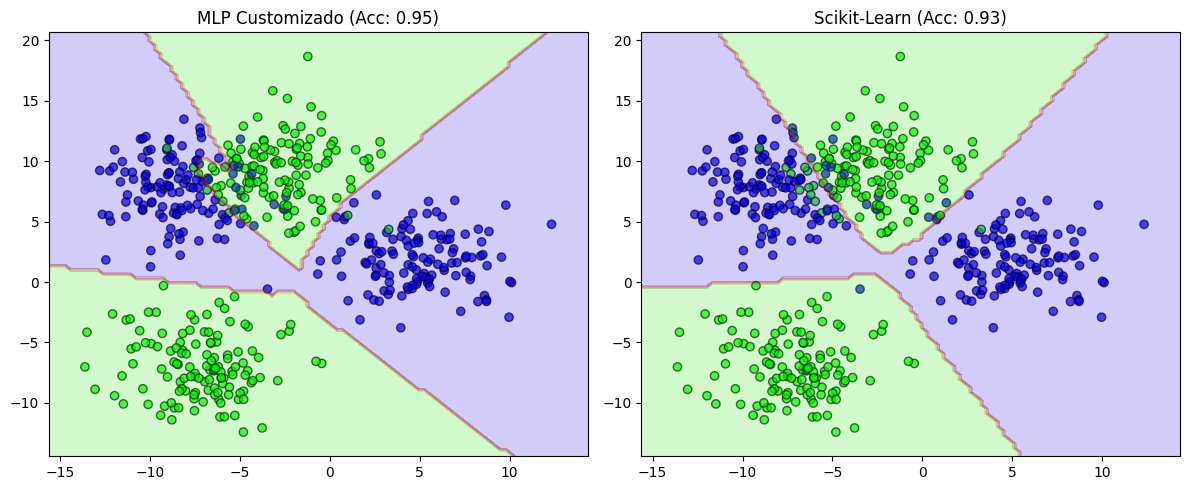

In [18]:
# ==========================================
# Funções de Plotagem e Comparação Visual
# ==========================================
def defineAxes(X):
    offset = 2
    min1, max1 = X[:,0].min()-offset, X[:,0].max()+offset
    min2, max2 = X[:,1].min()-offset, X[:,1].max()+offset
    return [min1, max1, min2, max2]

def plotPredictions(model, X):
    axes = defineAxes(X)
    x0s = np.linspace(axes[0], axes[1], 100)
    x1s = np.linspace(axes[2], axes[3], 100)
    x0, x1 = np.meshgrid(x0s, x1s)
    X_grid = np.c_[x0.ravel(), x1.ravel()]

    ypred = model.predict(X_grid).reshape(x0.shape)
    plt.contourf(x0, x1, ypred, cmap=plt.cm.brg, alpha=0.2)

plt.figure(figsize=(12, 5))

# Gráfico do Customizado
plt.subplot(1, 2, 1)
plt.title(f"MLP Customizado (Acc: {accuracy_score(y, y_pred_custom):.2f})")
plt.scatter(X[:,0], X[:,1], c=y, cmap=plt.cm.brg, edgecolors='k', alpha=0.7)
plotPredictions(model_custom, X)

# Gráfico do Scikit-Learn
plt.subplot(1, 2, 2)
plt.title(f"Scikit-Learn (Acc: {accuracy_score(y, y_pred_sklearn):.2f})")
plt.scatter(X[:,0], X[:,1], c=y, cmap=plt.cm.brg, edgecolors='k', alpha=0.7)
plotPredictions(model_sklearn, X)

plt.tight_layout()
plt.show()